# Spectral library entropy search

Query an indexed library with a synthetic peptide fragment spectrum.

An identity search first gates library entries by precursor mass, then compares fragment intensities. The Flash entropy index makes repeated queries efficient. This experiment adapts a mass-spectral search method first reported for metabolomics to invented peptide fragments.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import fragments, RESIDUES, PROTON, WATER
from ms_entropy import FlashEntropySearch

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

scores {'ADGLKVR': 0.0, 'PEPTIDE': 0.6636000275611877, 'PEPTEDI': 0.3752000033855438, 'TIDEPEP': 0.0}


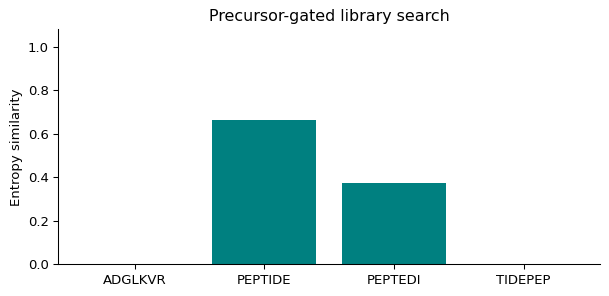

In [2]:
seqs = ["PEPTIDE", "PEPTEDI", "TIDEPEP", "ADGLKVR"]


def entry(seq):
    b, y = fragments(seq)
    mzs = np.r_[b, y]
    intens = np.r_[np.linspace(1, 3, len(b)), np.linspace(3, 2, len(y))]
    order = np.argsort(mzs)
    return {
        "precursor_mz": (sum(RESIDUES[c] for c in seq) + WATER + 2 * PROTON) / 2,
        "peaks": np.column_stack((mzs[order], intens[order])).astype(np.float32),
        "label": seq,
    }


lib = [entry(seq) for seq in seqs]
engine = FlashEntropySearch(max_ms2_tolerance_in_da=0.03)
indexed = engine.build_index(lib, clean_spectra=True)
q = entry(seqs[0])
q["peaks"][:, 0] += 0.001
scores = engine.search(
    q["precursor_mz"],
    q["peaks"],
    ms1_tolerance_in_da=0.01,
    ms2_tolerance_in_da=0.015,
    method="identity",
    precursor_ions_removal_da=None,
)["identity_search"]
labels = [spec["label"] for spec in indexed]
print("scores", dict(zip(labels, np.round(scores, 4).tolist())))
assert labels[int(np.argmax(scores))] == seqs[0]
fig, ax = plt.subplots(figsize=(6.3, 3), constrained_layout=True)
ax.bar(labels, scores, color="teal")
ax.set(ylabel="Entropy similarity", ylim=(0, 1.08), title="Precursor-gated library search")
plt.show()

## Interpreting the result

Some reordered peptides have the same precursor. Shared fragment peaks determine how well the search distinguishes these entries.

## Exercise

Compare the identity and open search scores for the different-mass library entry.

## References

[Li and Fiehn, Flash entropy search (2023)](https://doi.org/10.1038/s41592-023-02012-9)

[MS Entropy, library search interface](https://msentropy.readthedocs.io/en/latest/)